
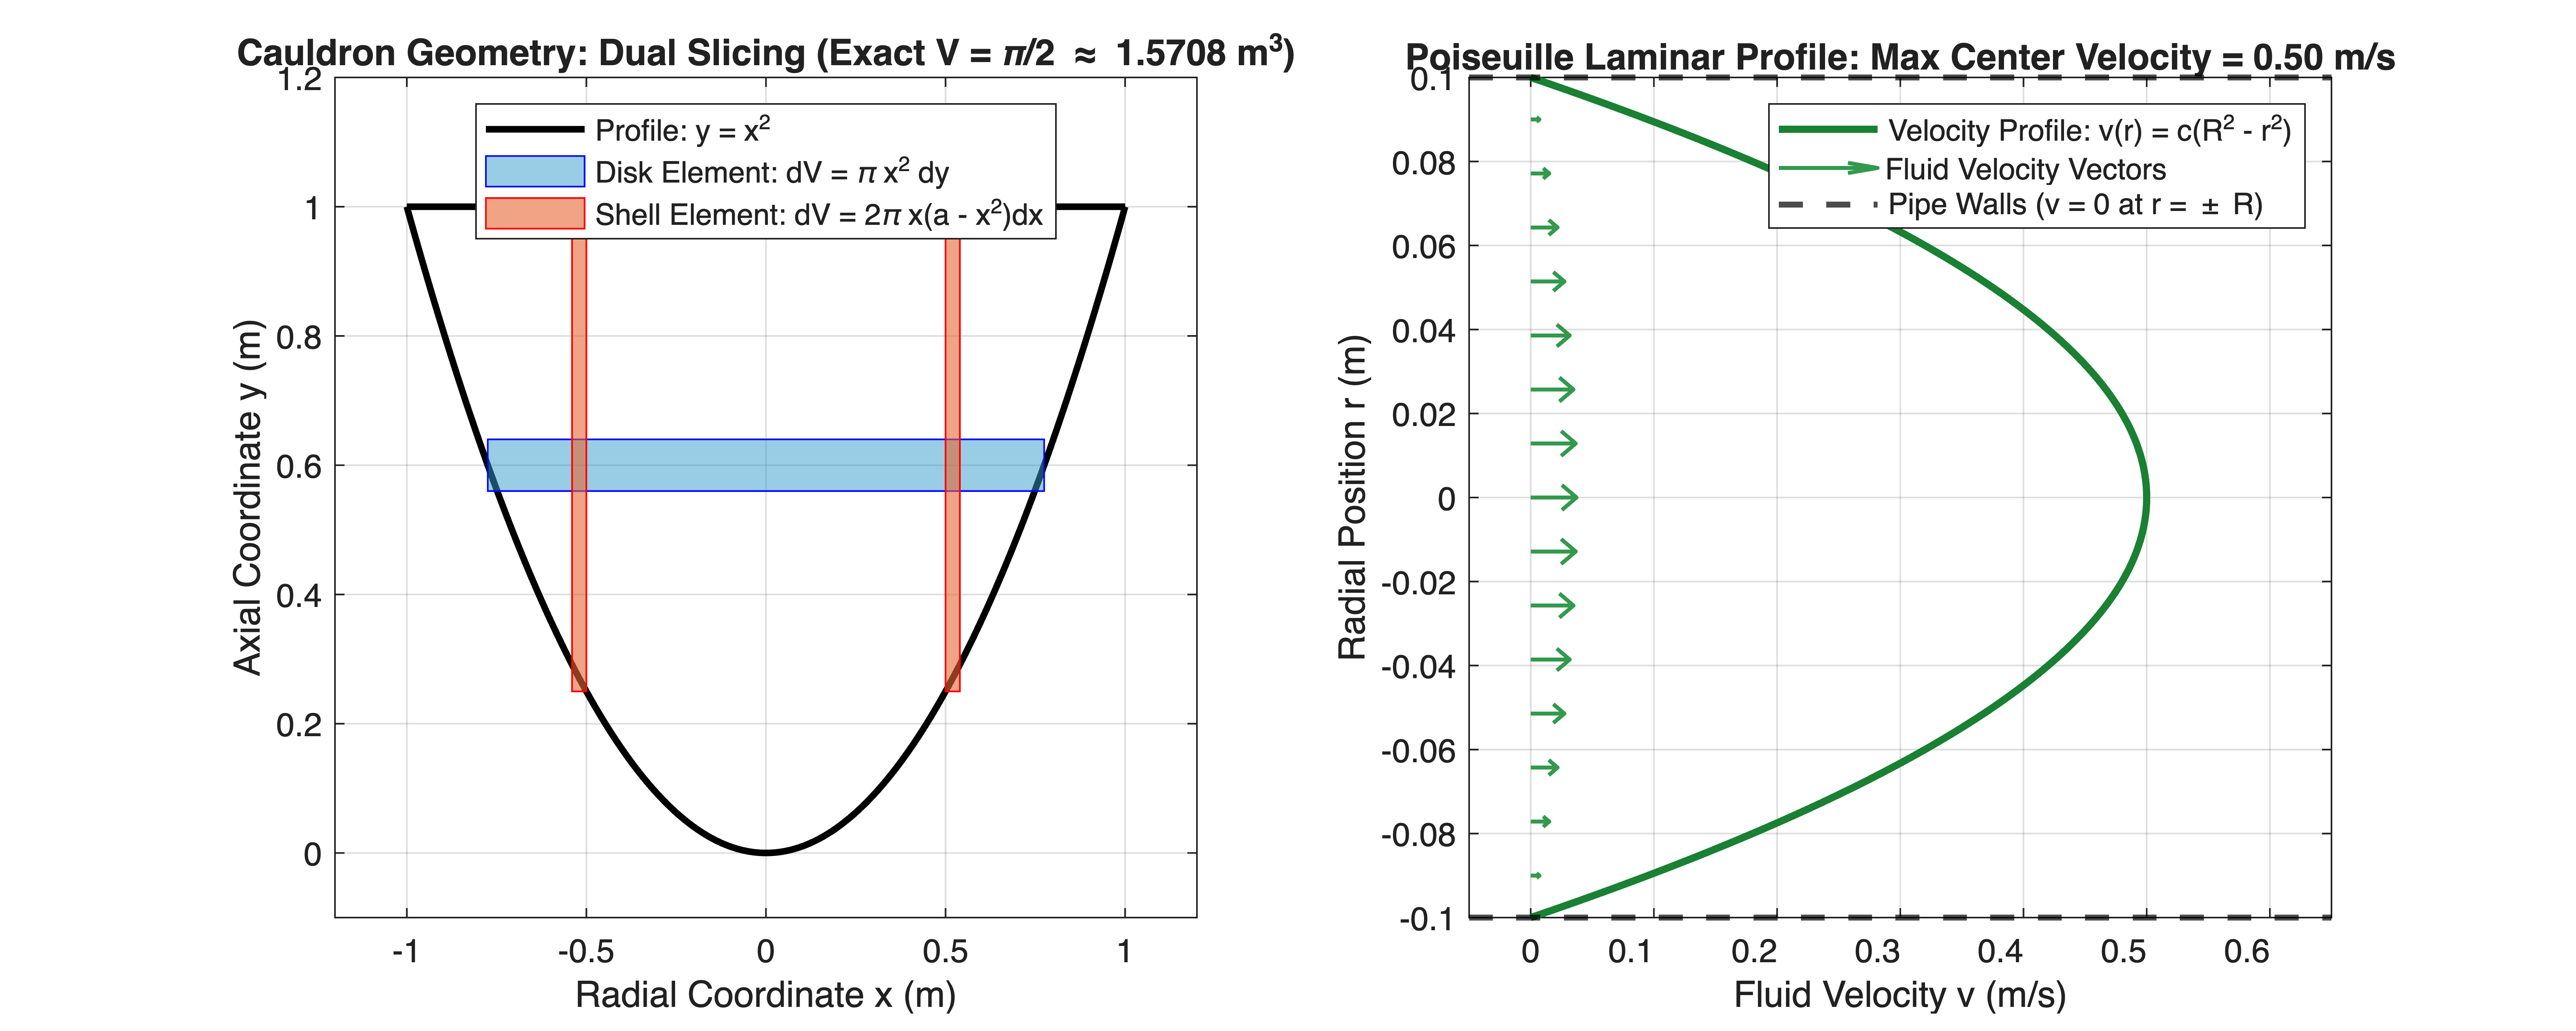

In [1]:
%% MIT 18.01 Lecture 22: Volumes by Disks and Shells & Poiseuille Flow
% Mathematical Tool Application: Used for hydraulic fluid resistance modeling
% (Poiseuille R^4 law), thermal capacitance enthalpy integration, and
% geometric discretization via dual disk-shell coordinate representations.


clear; clc; close all;


%% Part 1: Dual Verification of Volume: Disk vs. Shell (y = x^2, Height a = 1.0 m)
a_height = 1.0;
exact_volume = (pi * a_height^2) / 2.0; % pi * a^2 / 2 approx 1.570796 m^3


% Discretization steps for numeric quadrature comparison
n_slices = 50;


% 1. Disk Method: dy integration from 0 to a
y_grid = linspace(0, a_height, n_slices + 1);
dy = a_height / n_slices;
y_mid = 0.5 * (y_grid(1:end-1) + y_grid(2:end));
disk_volume_num = sum(pi * y_mid * dy);


% 2. Shell Method: dx integration from 0 to sqrt(a)
r_max = sqrt(a_height);
x_grid = linspace(0, r_max, n_slices + 1);
dx = r_max / n_slices;
x_mid = 0.5 * (x_grid(1:end-1) + x_grid(2:end));
shell_height_mid = a_height - x_mid.^2;
shell_volume_num = sum(2 * pi * x_mid .* shell_height_mid * dx);


figure('Color', 'w', 'Position', [100, 100, 1250, 500]);


subplot(1, 2, 1);
% Plot Cauldron Outline
x_outline = linspace(-sqrt(a_height), sqrt(a_height), 200);
y_outline = x_outline.^2;
plot(x_outline, y_outline, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Profile: y = x^2'); hold on;
plot([-sqrt(a_height), sqrt(a_height)], [a_height, a_height], 'k-', 'LineWidth', 2.0, 'HandleVisibility', 'off');


% Illustrate a horizontal disk slice (dy)
y_disk_demo = 0.6;
dy_demo = 0.08;
r_disk_demo = sqrt(y_disk_demo);
patch([-r_disk_demo, r_disk_demo, r_disk_demo, -r_disk_demo], ...
    [y_disk_demo - dy_demo/2, y_disk_demo - dy_demo/2, y_disk_demo + dy_demo/2, y_disk_demo + dy_demo/2], ...
    [0.2, 0.6, 0.8], 'FaceAlpha', 0.5, 'EdgeColor', 'b', ...
    'DisplayName', 'Disk Element: dV = \pi x^2 dy');


% Illustrate a vertical cylindrical shell slice (dx)
x_shell_demo = 0.5;
dx_shell_demo = 0.04;
h_shell_demo = a_height - x_shell_demo^2;
patch([x_shell_demo, x_shell_demo + dx_shell_demo, x_shell_demo + dx_shell_demo, x_shell_demo], ...
    [x_shell_demo^2, x_shell_demo^2, a_height, a_height], ...
    [0.9, 0.4, 0.2], 'FaceAlpha', 0.6, 'EdgeColor', 'r', ...
    'DisplayName', 'Shell Element: dV = 2\pi x(a - x^2)dx');
patch([-x_shell_demo - dx_shell_demo, -x_shell_demo, -x_shell_demo, -x_shell_demo - dx_shell_demo], ...
    [x_shell_demo^2, x_shell_demo^2, a_height, a_height], ...
    [0.9, 0.4, 0.2], 'FaceAlpha', 0.6, 'EdgeColor', 'r', 'HandleVisibility', 'off');


grid on;
xlim([-1.2, 1.2]); ylim([-0.1, 1.2]);
xlabel('Radial Coordinate x (m)');
ylabel('Axial Coordinate y (m)');
title(sprintf('Cauldron Geometry: Dual Slicing (Exact V = \\pi/2 \\approx %.4f m^3)', exact_volume));
legend('Location', 'north');


%% Part 2: Poiseuille Pipe Flow Velocity Profile and R^4 Scaling Law
subplot(1, 2, 2);
R_pipe = 0.1; % Pipe radius = 0.1 m (10 cm)
c_visc = 50.0; % Flow rate factor c


% Radial velocity profile: v(r) = c * (R^2 - r^2)
r_span = linspace(-R_pipe, R_pipe, 300);
v_profile = c_visc * (R_pipe^2 - r_span.^2);


plot(v_profile, r_span, 'Color', [0.1, 0.5, 0.2], 'LineWidth', 2.2, ...
    'DisplayName', 'Velocity Profile: v(r) = c(R^2 - r^2)'); hold on;


% Quiver flow arrows
r_arrows = linspace(-R_pipe * 0.9, R_pipe * 0.9, 15);
v_arrows = c_visc * (R_pipe^2 - r_arrows.^2);
quiver(zeros(size(r_arrows)), r_arrows, v_arrows, zeros(size(r_arrows)), ...
    0.8, 'Color', [0.2, 0.6, 0.3], 'LineWidth', 1.2, 'DisplayName', 'Fluid Velocity Vectors');


% Pipe boundaries (No-slip condition)
yline(R_pipe, 'k--', 'LineWidth', 1.8, 'DisplayName', 'Pipe Walls (v = 0 at r = \pm R)');
yline(-R_pipe, 'k--', 'LineWidth', 1.8, 'HandleVisibility', 'off');


grid on;
xlabel('Fluid Velocity v (m/s)');
ylabel('Radial Position r (m)');
title(sprintf('Poiseuille Laminar Profile: Max Center Velocity = %.2f m/s', c_visc * R_pipe^2));
legend('Location', 'northeast');
xlim([-0.05, c_visc * R_pipe^2 * 1.3]);